File Name: ggm_assessment.ipynb

Author:
    Debora Bisoglio
    B-Open Solutions

Date: August 2025

Description:
------------
This notebook computes the algorithm stability for the GGM product.

Usage:
------
To use this script, define the following parameters:
    
    - cslc_file_name
    - cmlc_file_name
    - cmlc_ndc_file_name
    - cmlc_direct_file_name
    - cmlc_emi_file_name


In [1]:
#!/usr/bin/python3 
import numpy as np
import scipy as sp
import os
import matplotlib.pyplot as plt
import dask.array as da

In [2]:
punto = np.array([2, 3])
LOS_ndims = 2

LOS = np.array([[1, 1], [1, 2]])
L = np.sqrt(np.sum(np.square(LOS), axis = 1))
LOS = LOS/(L[:, None]*np.ones(LOS_ndims)[None, :])

In [3]:
b = np.dot(LOS, punto)
epsilon = 10**(-4)
sol = np.linalg.lstsq(LOS, b)

/tmp/ipykernel_143332/1011669519.py:3: FutureWarning: `rcond` parameter will change to the default of machine precision times ``max(M, N)`` where M and N are the input matrix dimensions.
To use the future default and silence this warning we advise to pass `rcond=None`, to keep using the old, explicitly pass `rcond=-1`.
  sol = np.linalg.lstsq(LOS, b)


In [4]:
e = np.arange(1, 12)
sols = []
errs = []
for num in e:
    eps = 1/(10**(num))
    a = b + eps
    sol = np.linalg.lstsq(LOS, a)
    sols.append(sol[0])
    err = sol[0]-punto
    errs.append(np.linalg.norm(err)/np.linalg.norm(punto))
print(sols)
sigma = 1/10**(e)
print(sigma)
    

[array([2.05923591, 3.08218544]), array([2.00592359, 3.00821854]), array([2.00059236, 3.00082185]), array([2.00005924, 3.00008219]), array([2.00000592, 3.00000822]), array([2.00000059, 3.00000082]), array([2.00000006, 3.00000008]), array([2.00000001, 3.00000001]), array([2., 3.]), array([2., 3.]), array([2., 3.])]
[1.e-01 1.e-02 1.e-03 1.e-04 1.e-05 1.e-06 1.e-07 1.e-08 1.e-09 1.e-10
 1.e-11]


/tmp/ipykernel_143332/2072946501.py:7: FutureWarning: `rcond` parameter will change to the default of machine precision times ``max(M, N)`` where M and N are the input matrix dimensions.
To use the future default and silence this warning we advise to pass `rcond=None`, to keep using the old, explicitly pass `rcond=-1`.
  sol = np.linalg.lstsq(LOS, a)


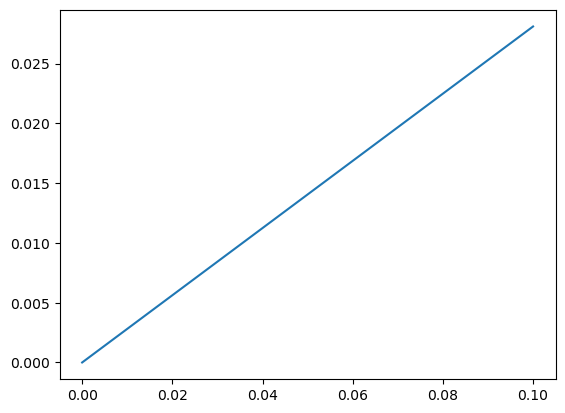

In [5]:
plt.plot(sigma, errs)

In [6]:
def ortogonale(vec):
    matr = np.array([[0, -1, 0], [1, 0, 0], [0, 0, 0]])
    return np.dot(matr, vec)

In [ ]:
def matrix():
    asc = np.array([-0.1-0.02*np.random.rand(), -0.65-0.07*np.random.rand(), 0.7+0.18*np.random.rand()])
    desc = np.array([-0.1-0.02*np.random.rand(), +0.65+0.07*np.random.rand(), 0.7+0.18*np.random.rand()])
    L = np.array([asc, ortogonale(asc), desc, ortogonale(desc)])

    LL = np.sqrt(np.sum(np.square(L), axis = 1))
    L = L/(LL[:, None]*np.ones(3)[None, :])
    return L 

In [8]:
def get_along_track_vector(vec):
    """
    Returns a unit vector orthogonal to `vec` (3D),
    with the constraint that the resulting vector lies in the XY plane (i.e., z = 0).
    This is done by projecting `vec` onto XY and rotating 90° in-plane.
    """
    v_xy = np.array([vec[0], vec[1]])
    if np.linalg.norm(v_xy) < 1e-8:
        raise ValueError("Cannot compute orthogonal vector: XY projection is near zero.")
    ortho_xy = np.array([-v_xy[1], v_xy[0], 0])
    ortho_unit = ortho_xy / np.linalg.norm(ortho_xy)
    return ortho_unit

def get_matrix():
    """
    Generates a matrix L of 4 unit LOS vectors:
    2 real (ASC and DESC), and 2 along-track vectors in the XY plane.
    Adds random variation to simulate realistic LOS differences.
    """
    asc = np.array([
        -0.1  - 0.02 * np.random.rand(), 
        -0.65 - 0.07 * np.random.rand(), 
        0.7   + 0.18 * np.random.rand()
    ])
    desc = np.array([
        -0.1  - 0.02 * np.random.rand(), 
        0.65  + 0.07 * np.random.rand(), 
        0.7   + 0.18 * np.random.rand()
    ])
    asc /= np.linalg.norm(asc)
    desc /= np.linalg.norm(desc)

    return np.array([
                asc,
                get_along_track_vector(asc),
                desc,
                get_along_track_vector(desc)
            ])

In [9]:
A = get_matrix()
A[0, 0] = 0
A[2, 0] = 0
A[0, :] /= np.linalg.norm(A[0, :])
A[2, :] /= np.linalg.norm(A[2, :])

In [10]:
d = np.array([np.random.normal(scale=0.5, size=100000), np.random.normal(scale=0.4, size=100000), np.random.normal(scale=0.5, size=100000), np.random.normal(scale=0.4, size=100000)])
V = np.array((0.005, 0.4, 0.005, 0.4))[..., None]
A_prime = A / (V ** 2)
d_prime = d / (V ** 2)

In [11]:
L_prime = np.linalg.inv(A_prime.transpose() @ A_prime) @ A_prime.transpose()
L = np.linalg.inv(A.transpose() @ A) @ A.transpose()
Y = L @ d
Y_prime = L_prime @ d_prime

In [12]:
print(np.std(Y, axis=1))
print(np.std(Y_prime, axis=1))

[0.28682852 0.50700713 0.47550844]
[0.28682734 0.52677961 0.47550813]


In [ ]:
def find_sigma(L, sigma):
    B = np.linalg.inv(L.transpose()@L)@L.transpose()
    return np.sqrt(B**2@sigma**2)

In [ ]:
def simulo_S1_100m():
    L = matrix()
    sigma = find_sigma(L, np.array([0.001, 0.04, 0.001, 0.04]))
    return sigma

In [ ]:
def simulo_S1_200m():
    L = matrix()
    sigma = find_sigma(L, np.array([0.0005, 0.02, 0.0005, 0.02]))
    return sigma

In [ ]:
def simulo_rosel_100m():
    L = matrix()
    sigma = find_sigma(L, np.array([0.002, 0.03, 0.002, 0.03]))
    return sigma

In [ ]:
def simulo_rosel_200m():
    L = matrix()
    sigma = find_sigma(L, np.array([0.001, 0.015, 0.001, 0.015]))
    return sigma

In [18]:
sigmas_S1_100m = []
sigmas_S1_200m = []
sigmas_rosel_100m = []
sigmas_rosel_200m = []
for i in range(100000):
    sigmas_S1_100m.append(simulo_S1_100m())
    sigmas_S1_200m.append(simulo_S1_200m())
    sigmas_rosel_100m.append(simulo_rosel_100m())
    sigmas_rosel_200m.append(simulo_rosel_200m())
    
sigmas_S1_100m = np.array(sigmas_S1_100m).transpose()
sigmas_S1_200m = np.array(sigmas_S1_200m).transpose()
sigmas_rosel_100m = np.array(sigmas_rosel_100m).transpose()
sigmas_rosel_200m = np.array(sigmas_rosel_200m).transpose()


In [19]:
print("rose-l 100m")
print(sigmas_rosel_100m)
print("rose-l 200m")
print(sigmas_rosel_200m)
print("S1 100m")
print(sigmas_S1_100m)
print("S1 200m")
print(sigmas_S1_200m)

rose-l 100m
[[0.0214943  0.02147681 0.02148565 ... 0.0215124  0.02150871 0.02146678]
 [0.00798361 0.00803323 0.0080108  ... 0.00763827 0.00792994 0.00705097]
 [0.00352397 0.00335974 0.003452   ... 0.00384505 0.00370216 0.00364564]]
rose-l 200m
[[0.01073789 0.01074393 0.01074603 ... 0.01074706 0.01075306 0.01074055]
 [0.00380234 0.00386097 0.00371384 ... 0.00408018 0.00403867 0.00390787]
 [0.00173878 0.00177756 0.0018717  ... 0.00173616 0.00177109 0.00174378]]
S1 100m
[[0.02861783 0.02865664 0.02865539 ... 0.02865015 0.02863722 0.02862309]
 [0.00968213 0.01104304 0.00940533 ... 0.01061497 0.01058622 0.01014415]
 [0.00391485 0.00382638 0.00444731 ... 0.00395661 0.00380177 0.0038127 ]]
S1 200m
[[0.01433173 0.01433249 0.01433236 ... 0.01429329 0.01433078 0.01433387]
 [0.00526003 0.00529284 0.00550392 ... 0.00445385 0.00567401 0.00511107]
 [0.00204502 0.00204153 0.00196541 ... 0.00194171 0.00192405 0.00211334]]


In [20]:
print("rose-l 100m")
print(np.max(sigmas_rosel_100m, axis = 1))
print("rose-l 200m")
print(np.max(sigmas_rosel_200m, axis= 1))
print("S1 100m")
print(np.max(sigmas_S1_100m, axis = 1))
print("S1 200m")
print(np.max(sigmas_S1_200m, axis = 1))

rose-l 100m
[0.02156631 0.00983959 0.00417923]
rose-l 200m
[0.01078213 0.00499456 0.00207506]
S1 100m
[0.0287532  0.01277374 0.00496788]
S1 200m
[0.01437776 0.00645788 0.00247922]
